# Semana 1: Revisión de POO I — Diagnóstico, Refactorización y Calidad de Código

In [ ]:
# SU SOLUCIÓN REFACTORIZADA — Práctica S1, Actividad 2
from dataclasses import dataclass


@dataclass
class Nota:
    curso: str
    calificacion: float


class Estudiante:
    def __init__(self, nombre: str, codigo: int, escuela: str):
        self._nombre = nombre
        self._codigo = codigo
        self._escuela = escuela
        self._historial_notas: list[Nota] = []

    @property
    def nombre(self) -> str:
        return self._nombre

    def agregar_nota(self, curso: str, calificacion: float) -> None:
        if not (0 <= calificacion <= 20):
            raise ValueError(f"La calificación debe estar en el rango [0, 20]. Valor recibido: {calificacion}")

        self._historial_notas.append(Nota(curso, calificacion))

    def calcular_ppa(self) -> float:
        if not self._historial_notas:
            return 0.0

        suma_calificaciones = sum(nota.calificacion for nota in self._historial_notas)
        return suma_calificaciones / len(self._historial_notas)

    def __str__(self) -> str:
        lineas = [
            f"Estudiante: {self._nombre} | Código: {self._codigo} | Escuela: {self._escuela}",
            "Notas:"
        ]
        for nota in self._historial_notas:
            lineas.append(f"  - {nota.curso}: {nota.calificacion}")
        return "\n".join(lineas)


# Prueba — debe ejecutar sin errores:
if __name__ == "__main__":
    e = Estudiante("Juan Carlos Mamani Quispe", 20210500, "Ing. Sistemas")
    e.agregar_nota("POO II", 16)
    e.agregar_nota("Base de Datos I", 14)
    print(e)
    print(f"PPA: {e.calcular_ppa():.2f}")

    try:
        e.agregar_nota("Redes", 25) # debe lanzar ValueError
    except ValueError as ex:
        print(f"Error capturado correctamente: {ex}")

Estudiante: Juan Carlos Mamani Quispe | Código: 20210500 | Escuela: Ing. Sistemas
Notas:
  - POO II: 16
  - Base de Datos I: 14
PPA: 15.00
Error capturado correctamente: La calificación debe estar en el rango [0, 20]. Valor recibido: 25


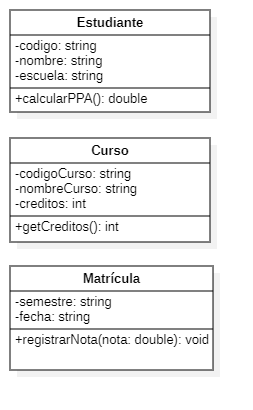

# Semana 2: Abstracción y Encapsulamiento: Invariantes, propiedades y Diseño por Responsabilidades

In [ ]:
import re
from datetime import date

# --- Clase Curso ---
class Curso:
    _PATRON_CODIGO = re.compile(r"^SIS\d{3}$")

    def __init__(self, codigo: str, nombre: str, creditos: int, cupos_maximo: int):
        self.codigo = codigo
        self.nombre = nombre
        self.creditos = creditos
        self.cupos_maximo = cupos_maximo
        self.__inscritos = 0

    @property
    def codigo(self): return self.__codigo
    @codigo.setter
    def codigo(self, valor):
        if not self._PATRON_CODIGO.match(valor):
            raise ValueError("Código inválido, debe ser SIS###")
        self.__codigo = valor

    @property
    def nombre(self): return self.__nombre
    @nombre.setter
    def nombre(self, valor):
        if not valor.strip():
            raise ValueError("El nombre no puede estar vacío")
        self.__nombre = valor

    @property
    def creditos(self): return self.__creditos
    @creditos.setter
    def creditos(self, valor):
        if not (1 <= valor <= 6):
            raise ValueError("Créditos fuera de rango [1,6]")
        self.__creditos = valor

    @property
    def cupos_maximo(self): return self.__cupos_maximo
    @cupos_maximo.setter
    def cupos_maximo(self, valor):
        if not (1 <= valor <= 50):
            raise ValueError("Cupos fuera de rango [1,50]")
        self.__cupos_maximo = valor

    @property
    def inscritos(self): return self.__inscritos
    @property
    def cupos_disponibles(self): return self.__cupos_maximo - self.__inscritos
    @property
    def esta_lleno(self): return self.__inscritos >= self.__cupos_maximo

    def inscribir_estudiante(self):
        if self.esta_lleno:
            raise RuntimeError("Curso sin cupos disponibles")
        self.__inscritos += 1

    def __str__(self):
        return f"{self.__codigo} - {self.__nombre} ({self.__creditos} cr) [{self.__inscritos}/{self.__cupos_maximo}]"


# --- Clase Docente ---
class Docente:
    _MAX_CURSOS = 3

    def __init__(self, dni: str, nombres: str, apellidos: str, correo: str, fecha_nac: date):
        self.dni = dni
        self.nombres = nombres
        self.apellidos = apellidos
        self.correo = correo
        self.__fecha_nac = fecha_nac
        self.__cursos: list[Curso] = []

    @property
    def dni(self): return self.__dni
    @dni.setter
    def dni(self, valor):
        if not valor.isdigit() or len(valor) != 8:
            raise ValueError("DNI inválido, debe tener 8 dígitos")
        self.__dni = valor

    @property
    def correo(self): return self.__correo
    @correo.setter
    def correo(self, valor):
        if not valor.endswith("@unap.edu.pe"):
            raise ValueError("Correo debe terminar en @unap.edu.pe")
        self.__correo = valor

    @property
    def nombre_completo(self): return f"{self.apellidos}, {self.nombres}"
    @property
    def edad(self):
        hoy = date.today()
        edad = hoy.year - self.__fecha_nac.year
        if (hoy.month, hoy.day) < (self.__fecha_nac.month, self.__fecha_nac.day):
            edad -= 1
        return edad
    @property
    def total_creditos(self): return sum(c.creditos for c in self.__cursos)

    def asignar_curso(self, curso: Curso):
        if len(self.__cursos) >= self._MAX_CURSOS:
            raise RuntimeError("Máximo de cursos asignados alcanzado")
        self.__cursos.append(curso)


# --- Clase Estudiante ---
class Estudiante:
    def __init__(self, nombre: str, apellidos: str):
        self.nombre = nombre
        self.apellidos = apellidos

    @property
    def nombre(self): return self.__nombre
    @nombre.setter
    def nombre(self, valor):
        if not valor.strip():
            raise ValueError("El nombre no puede estar vacío")
        self.__nombre = valor

    @property
    def apellidos(self): return self.__apellidos
    @apellidos.setter
    def apellidos(self, valor):
        if not valor.strip():
            raise ValueError("Los apellidos no pueden estar vacíos")
        self.__apellidos = valor

    @property
    def nombre_completo(self): return f"{self.__apellidos}, {self.__nombre}"
    @property
    def iniciales(self): return f"{self.__nombre[0]}.{self.__apellidos[0]}."


# --- Bloque de pruebas ---
curso = Curso("SIS206", "POO II", 4, 30)
print(curso)
curso.inscribir_estudiante()
curso.inscribir_estudiante()
print("Inscritos:", curso.inscritos)
print("Cupos disponibles:", curso.cupos_disponibles)

docente = Docente("12345678", "Aldo Hernan", "Zanabria Galvez", "azanabria@unap.edu.pe", date(1980, 5, 14))
docente.asignar_curso(curso)
print("Docente:", docente.nombre_completo, "| Edad:", docente.edad, "| Créditos:", docente.total_creditos)

estudiante = Estudiante("Juan", "Mamani Quispe")
print("Estudiante:", estudiante.nombre_completo, "| Iniciales:", estudiante.iniciales)


SIS206 - POO II (4 cr) [0/30]
Inscritos: 2
Cupos disponibles: 28
Docente: Zanabria Galvez, Aldo Hernan | Edad: 46 | Créditos: 4
Estudiante: Mamani Quispe, Juan | Iniciales: J.M.


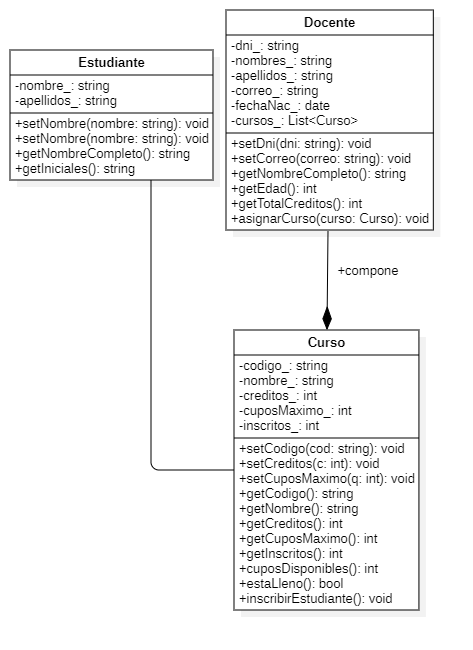